# 05 – Per-nucleus comparison: pretrained vs. fine-tuned Cellpose-SAM

**Purpose:** Build a table with **one row per annotated nucleus and model**, as the basis for a paired
statistical comparison in R. Notebooks 03/04 only report per-frame summaries; for a paired test, the same
nucleus must be compared under both models.

**Input:** sequence 01 (gold truth, tracking reference), fine-tuned model from Kaggle in `models/`
**Output:** `results/per_nucleus_iou_seq01.csv` (tracked by git) → analysed in `R/01_paired_comparison.R`

### Variables per nucleus
| Column | Meaning |
|---|---|
| `frame`, `gt_label` | identifies the annotated nucleus |
| `full_frame` | frame fully annotated (13, 52) or partial |
| `area_px` | size of the reference nucleus |
| `track` | track ID from the tracking markers (cell identity over time) |
| `frames_to_division` | frames to the nearest division (before or after); NaN if none in the movie |
| `model` | `pretrained` or `fine-tuned` |
| `best_iou` | highest IoU with any predicted nucleus (0 if no overlap) |
| `matched` | `best_iou > 0.5` |

## 1. Imports and settings

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from skimage.segmentation import relabel_sequential
from skimage.measure import regionprops_table

DATA = Path("../data/raw/Fluo-N2DL-HeLa")
RESULTS = Path("../results")
CACHE = Path("../data/derived")              # predictions are cached here (not tracked by git)
MODEL_FT = Path("../models/cpsam_hela_seq02") # fine-tuned model downloaded from Kaggle
SEQ = "01"
FULL_FRAMES = [13, 52]
IOU_THRESHOLD = 0.5

print("fine-tuned model found:", MODEL_FT.exists())

fine-tuned model found: True


## 2. Load gold-truth frames, tracking markers and lineage

In [2]:
def frame_number(path):
    return int("".join(c for c in path.stem if c.isdigit()))

gt_files = sorted((DATA / f"{SEQ}_GT" / "SEG").glob("man_seg*.tif"))
frames = [frame_number(f) for f in gt_files]
gt  = {t: tifffile.imread(f) for t, f in zip(frames, gt_files)}
raw = {t: tifffile.imread(DATA / SEQ / f"t{t:03d}.tif") for t in frames}
tra = {t: tifffile.imread(DATA / f"{SEQ}_GT" / "TRA" / f"man_track{t:03d}.tif") for t in frames}

tracks = pd.read_csv(DATA / f"{SEQ}_GT" / "TRA" / "man_track.txt", sep=r"\s+", header=None,
                     names=["track", "begin", "end", "parent"])
n_children = tracks.loc[tracks["parent"] > 0, "parent"].value_counts()
tracks["divides"] = tracks["track"].map(n_children).fillna(0) >= 2   # ends in a division
tracks["born_by_division"] = tracks["parent"] > 0
tracks = tracks.set_index("track")
print(f"{len(frames)} GT frames, {len(tracks)} tracks")

28 GT frames, 265 tracks


## 3. Predictions of both models (cached)
Running both models on 28 frames takes about 15–20 min on the M2. The results are saved once to
`data/derived/` and reloaded on later runs.

In [3]:
from cellpose import models

# Cellpose silently falls back to the default model if the path does not exist → check explicitly
assert MODEL_FT.is_file(), f"fine-tuned model not found: {MODEL_FT.resolve()}"
print(f"fine-tuned model: {MODEL_FT.name}, {MODEL_FT.stat().st_size / 1e9:.2f} GB")

CACHE.mkdir(parents=True, exist_ok=True)
cache_file = CACHE / f"predictions_seq{SEQ}.npz"

if cache_file.exists():
    z = np.load(cache_file)
    pred = {name: {t: z[f"{name}_{t}"] for t in frames} for name in ["pretrained", "fine-tuned"]}
    print("loaded cached predictions")
else:
    nets = {"pretrained": models.CellposeModel(gpu=True),
            "fine-tuned": models.CellposeModel(gpu=True, pretrained_model=str(MODEL_FT))}
    pred = {}
    for name, m in nets.items():
        pred[name] = {}
        t0 = time.time()
        for i, t in enumerate(frames, 1):
            pred[name][t] = m.eval(raw[t])[0]
            print(f"{name} [{i}/{len(frames)}] frame {t}: {pred[name][t].max()} nuclei, "
                  f"{time.time() - t0:.0f} s", flush=True)
    np.savez_compressed(cache_file, **{f"{n}_{t}": pred[n][t] for n in pred for t in frames})
    print("saved:", cache_file)

fine-tuned model: cpsam_hela_seq02, 1.22 GB
loaded cached predictions


## 4. Best IoU per reference nucleus
For every annotated nucleus: the highest IoU with any predicted nucleus. The IoU table is the same as in
notebook 03; `relabel_sequential` also returns the mapping back to the original label IDs.

In [4]:
def iou_matrix(gt_lab, pred_lab):
    n_gt, n_pred = int(gt_lab.max()), int(pred_lab.max())
    codes = gt_lab.ravel().astype(np.int64) * (n_pred + 1) + pred_lab.ravel().astype(np.int64)
    overlap = np.bincount(codes, minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1)
    union = overlap.sum(axis=1, keepdims=True) + overlap.sum(axis=0, keepdims=True) - overlap
    return (overlap / np.maximum(union, 1))[1:, 1:]


def frames_to_division(track_id, t):
    """Frames to the nearest division event of this cell (its birth or its own division)."""
    if track_id not in tracks.index:
        return np.nan
    tr = tracks.loc[track_id]
    d = []
    if tr["born_by_division"]:
        d.append(t - tr["begin"])     # frames since birth
    if tr["divides"]:
        d.append(tr["end"] - t)       # frames until own division
    return min(d) if d else np.nan


rows = []
for t in frames:
    g, _, inv = relabel_sequential(gt[t])        # inv[i] = original label of relabelled i
    props = regionprops_table(g, intensity_image=tra[t], properties=["label", "area", "intensity_max"])
    for name in pred:
        p = relabel_sequential(pred[name][t])[0]
        iou = iou_matrix(g, p)
        best = iou.max(axis=1) if iou.shape[1] else np.zeros(iou.shape[0])
        for lab, area, trk in zip(props["label"], props["area"], props["intensity_max"].astype(int)):
            rows.append({
                "frame": t, "gt_label": int(inv[lab]), "full_frame": t in FULL_FRAMES,
                "area_px": int(area), "track": trk, "frames_to_division": frames_to_division(trk, t),
                "model": name, "best_iou": float(best[lab - 1]),
                "matched": bool(best[lab - 1] > IOU_THRESHOLD),
            })

nuc = pd.DataFrame(rows)
print(nuc.groupby("model")[["best_iou", "matched"]].mean().round(3))
print("nuclei per model:", nuc.groupby("model").size().to_dict(),
      "| without track ID:", (nuc["track"] == 0).sum() // 2)

            best_iou  matched
model                        
fine-tuned     0.816    0.914
pretrained     0.787    0.935
nuclei per model: {'fine-tuned': 491, 'pretrained': 491} | without track ID: 0


## 5. Paired view
Each point is one nucleus. Above the diagonal = better after fine-tuning.
The dashed lines mark the matching threshold (IoU 0.5).

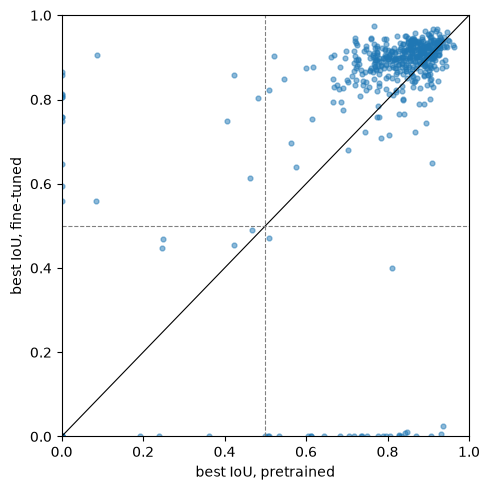

fine-tuned matched  False  True 
pretrained matched              
False                  14     18
True                   28    431


In [5]:
wide = nuc.pivot_table(index=["frame", "gt_label"], columns="model", values="best_iou").reset_index()
wide = wide.merge(nuc[nuc["model"] == "pretrained"][["frame", "gt_label", "full_frame", "frames_to_division"]],
                  on=["frame", "gt_label"])

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(wide["pretrained"], wide["fine-tuned"], s=12, alpha=0.5)
ax.plot([0, 1], [0, 1], color="k", lw=0.8)
ax.axvline(IOU_THRESHOLD, ls="--", color="grey", lw=0.8)
ax.axhline(IOU_THRESHOLD, ls="--", color="grey", lw=0.8)
ax.set_xlabel("best IoU, pretrained"); ax.set_ylabel("best IoU, fine-tuned")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(RESULTS / "figures" / "paired_iou_seq01.png", dpi=150)
plt.show()

# 2x2 table of detections (basis for McNemar's test)
m = nuc.pivot_table(index=["frame", "gt_label"], columns="model", values="matched").astype(bool)
print(pd.crosstab(m["pretrained"], m["fine-tuned"], rownames=["pretrained matched"],
                  colnames=["fine-tuned matched"]))

## 6. Export for R

In [6]:
out = RESULTS / f"per_nucleus_iou_seq{SEQ}.csv"
nuc.to_csv(out, index=False)
print("saved:", out, "|", len(nuc), "rows")

saved: ../results/per_nucleus_iou_seq01.csv | 982 rows


## 7. Lost nuclei (optional, napari)
Nuclei found by the pretrained but not by the fine-tuned model – to check visually why they were lost.

In [7]:
lost = wide[(wide["pretrained"] > IOU_THRESHOLD) & (wide["fine-tuned"] <= IOU_THRESHOLD)]
print(lost[["frame", "gt_label", "pretrained", "fine-tuned", "frames_to_division"]].round(2).to_string(index=False))

 frame  gt_label  pretrained  fine-tuned  frames_to_division
    13        52        0.83        0.00                 NaN
    14         2        0.64        0.00                 1.0
    20         5        0.84        0.01                 NaN
    21         1        0.81        0.00                 0.0
    22         1        0.75        0.00                 0.0
    22         9        0.68        0.00                 0.0
    23         2        0.87        0.00                 0.0
    23         5        0.80        0.00                 0.0
    23        11        0.85        0.01                 NaN
    38         7        0.61        0.00                39.0
    38        10        0.51        0.00                 NaN
    38        11        0.72        0.00                 NaN
    39        12        0.51        0.47                 NaN
    40         8        0.81        0.40                 NaN
    52        66        0.83        0.00                 NaN
    52       108        

In [8]:
%gui qt
import napari

t = int(lost["frame"].iloc[0])        # first frame with a lost nucleus; change as needed
lo, hi = np.percentile(raw[t], [1, 99.8])
viewer = napari.Viewer()
viewer.add_image(raw[t], name=f"raw t{t}", colormap="gray", contrast_limits=(lo, hi))
viewer.add_labels(gt[t], name="gold truth")
viewer.add_labels(pred["pretrained"][t], name="pretrained", visible=False)
viewer.add_labels(pred["fine-tuned"][t], name="fine-tuned", visible=False)
lost_ids = lost.loc[lost["frame"] == t, "gt_label"].to_numpy()
viewer.add_labels(np.where(np.isin(gt[t], lost_ids), gt[t], 0), name="lost after fine-tuning")

<Labels layer 'lost after fine-tuning' at 0x70173ed0a0>

## 8. Are the lost nuclei missing from the silver truth?
Hypothesis: the fine-tuned model learned the silver truth's *omissions*. If a nucleus is missing from the
training masks, the network learns "background" there. Then the nuclei lost after fine-tuning should be
missing from the silver truth more often than nuclei found by both models.

Silver truth of sequence 01 is used here only for this check – it played no role in training (sequence 02).

In [9]:
from scipy.stats import fisher_exact

# best IoU of the silver truth with every gold-truth nucleus (same matching as for the models)
st = {t: tifffile.imread(DATA / f"{SEQ}_ST" / "SEG" / f"man_seg{t:03d}.tif") for t in frames}
st_rows = []
for t in frames:
    g, _, inv = relabel_sequential(gt[t])
    s = relabel_sequential(st[t])[0]
    iou = iou_matrix(g, s)
    best = iou.max(axis=1) if iou.shape[1] else np.zeros(iou.shape[0])
    for i, b in enumerate(best, start=1):
        st_rows.append({"frame": t, "gt_label": int(inv[i]), "st_iou": float(b)})
st_df = pd.DataFrame(st_rows)

cmp = wide.merge(st_df, on=["frame", "gt_label"])
pre_ok = cmp["pretrained"] > IOU_THRESHOLD
ft_ok = cmp["fine-tuned"] > IOU_THRESHOLD
cmp["group"] = np.select([pre_ok & ~ft_ok, ~pre_ok & ft_ok, pre_ok & ft_ok],
                         ["lost", "gained", "found by both"], default="missed by both")
cmp["in_silver_truth"] = cmp["st_iou"] > IOU_THRESHOLD

print(pd.crosstab(cmp["group"], cmp["in_silver_truth"], margins=True))
print()
print(cmp.groupby("group")["st_iou"].describe()[["count", "mean", "25%", "50%", "75%"]].round(2))

# lost vs. found by both: is "missing from the silver truth" more frequent among the lost nuclei?
sub = cmp[cmp["group"].isin(["lost", "found by both"])]
table = (pd.crosstab(sub["group"] == "lost", ~sub["in_silver_truth"])
           .reindex(index=[True, False], columns=[True, False], fill_value=0))   # always 2x2
odds, p = fisher_exact(table.to_numpy())
print(f"\nFisher's exact test (lost vs. found by both  x  missing from silver truth): "
      f"odds ratio {odds:.1f}, p = {p:.2g}")


in_silver_truth  False  True  All
group                            
found by both        0   431  431
gained               0    18   18
lost                 0    28   28
missed by both       2    12   14
All                  2   489  491

                count  mean   25%   50%   75%
group                                        
found by both   431.0  0.90  0.88  0.91  0.93
gained           18.0  0.77  0.73  0.79  0.82
lost             28.0  0.81  0.76  0.82  0.89
missed by both   14.0  0.74  0.70  0.79  0.84

Fisher's exact test (lost vs. found by both  x  missing from silver truth): odds ratio nan, p = 1


## Results
*(to be filled in after running)*